# Model Training — Feature Engineering (Part A, Step 3)

**Objective:** on top of the clean, harmonized dataset (`data/processed/happiness_unified.csv`,
781 × 9), pick the model features, prove there is no target leakage, test whether the report
year earns a slot among the features, and define the preprocessing as an sklearn `Pipeline`
with a frozen feature order that training and streaming inference must share.

**Reading order of the project notebooks:** `eda.ipynb` (raw-files audit) →
`cleaning.ipynb` (builds the unified dataset) → this notebook.

This section does NOT save a model artifact nor a train/test split file; those come in the
model-training section that continues in this same notebook. Nothing here touches `data/raw/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Project root (this notebook lives in notebooks/ under the repo root)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "happiness_unified.csv"   # cleanup output; never the raw CSVs

df = pd.read_csv(DATA)
UNIFIED = ["country", "year", "gdp", "family", "health",
           "freedom", "generosity", "corruption", "happiness_score"]
NUMERIC = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]
TARGET = "happiness_score"

assert df.shape == (781, 9), f"unexpected processed shape: {df.shape}"
assert list(df.columns) == UNIFIED, "processed file does not match the unified schema"
assert df.isna().sum().sum() == 0, "missing values found in the clean dataset"
assert df.duplicated(["country", "year"]).sum() == 0, "duplicated (country, year) keys"

# Visualization style: exactly the same minimal look used in eda.ipynb
sns.set_theme(style="white", rc={
    "axes.grid": True, "grid.color": "#EAEAEA", "grid.linewidth": 0.8,
    "axes.edgecolor": "#CCCCCC",
    "text.color": "#333333", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "axes.titlesize": 11.5, "axes.titlecolor": "#2B2B2B",
})
YEAR_PALETTE = {2015: "#B8653B", 2016: "#3E78B2", 2017: "#767E8A",
                2018: "#468966", 2019: "#B8863B"}
FEATURE_LABELS = {
    "gdp": "GDP per Capita", "family": "Social Support (Family)",
    "health": "Healthy Life Expectancy", "freedom": "Freedom",
    "generosity": "Generosity", "corruption": "Perceptions of Corruption",
    "happiness_score": "Happiness Score (Target)", "year": "Report Year",
}

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
print("data loaded:", df.shape, "from", DATA)

data loaded: (781, 9) from C:\Users\juans\Downloads\ETL - Trabajos\Corte3\Workshop-3\data\processed\happiness_unified.csv


## 4.1 Descriptive statistics and relationship visuals

Descriptives over the clean 781-row dataset, then a factor-by-factor view against the
target and the correlation matrix. All figures reuse the same minimal style already
established in `eda.ipynb` (white background, soft `#EAEAEA` grid, no outer frames).

In [2]:
describe = df[NUMERIC].describe().T.round(3)
describe.index = [FEATURE_LABELS[c] for c in describe.index]
display(describe)

rows_by_year = df.groupby("year").size()
print()
print("rows per report year:", rows_by_year.to_dict())

,count,mean,std,min,25%,50%,75%,max
GDP per Capita,781.0,0.915,0.405,0.000,0.605,0.982,1.234,1.871
Social Support (Family),781.0,1.079,0.330,0.000,0.870,1.125,1.328,1.644
Healthy Life Expectancy,781.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
Freedom,781.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
Generosity,781.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838
Perceptions of Corruption,781.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552
Happiness Score (Target),781.0,5.377,1.127,2.693,4.509,5.321,6.182,7.769



rows per report year: {2015: 158, 2016: 157, 2017: 155, 2018: 155, 2019: 156}


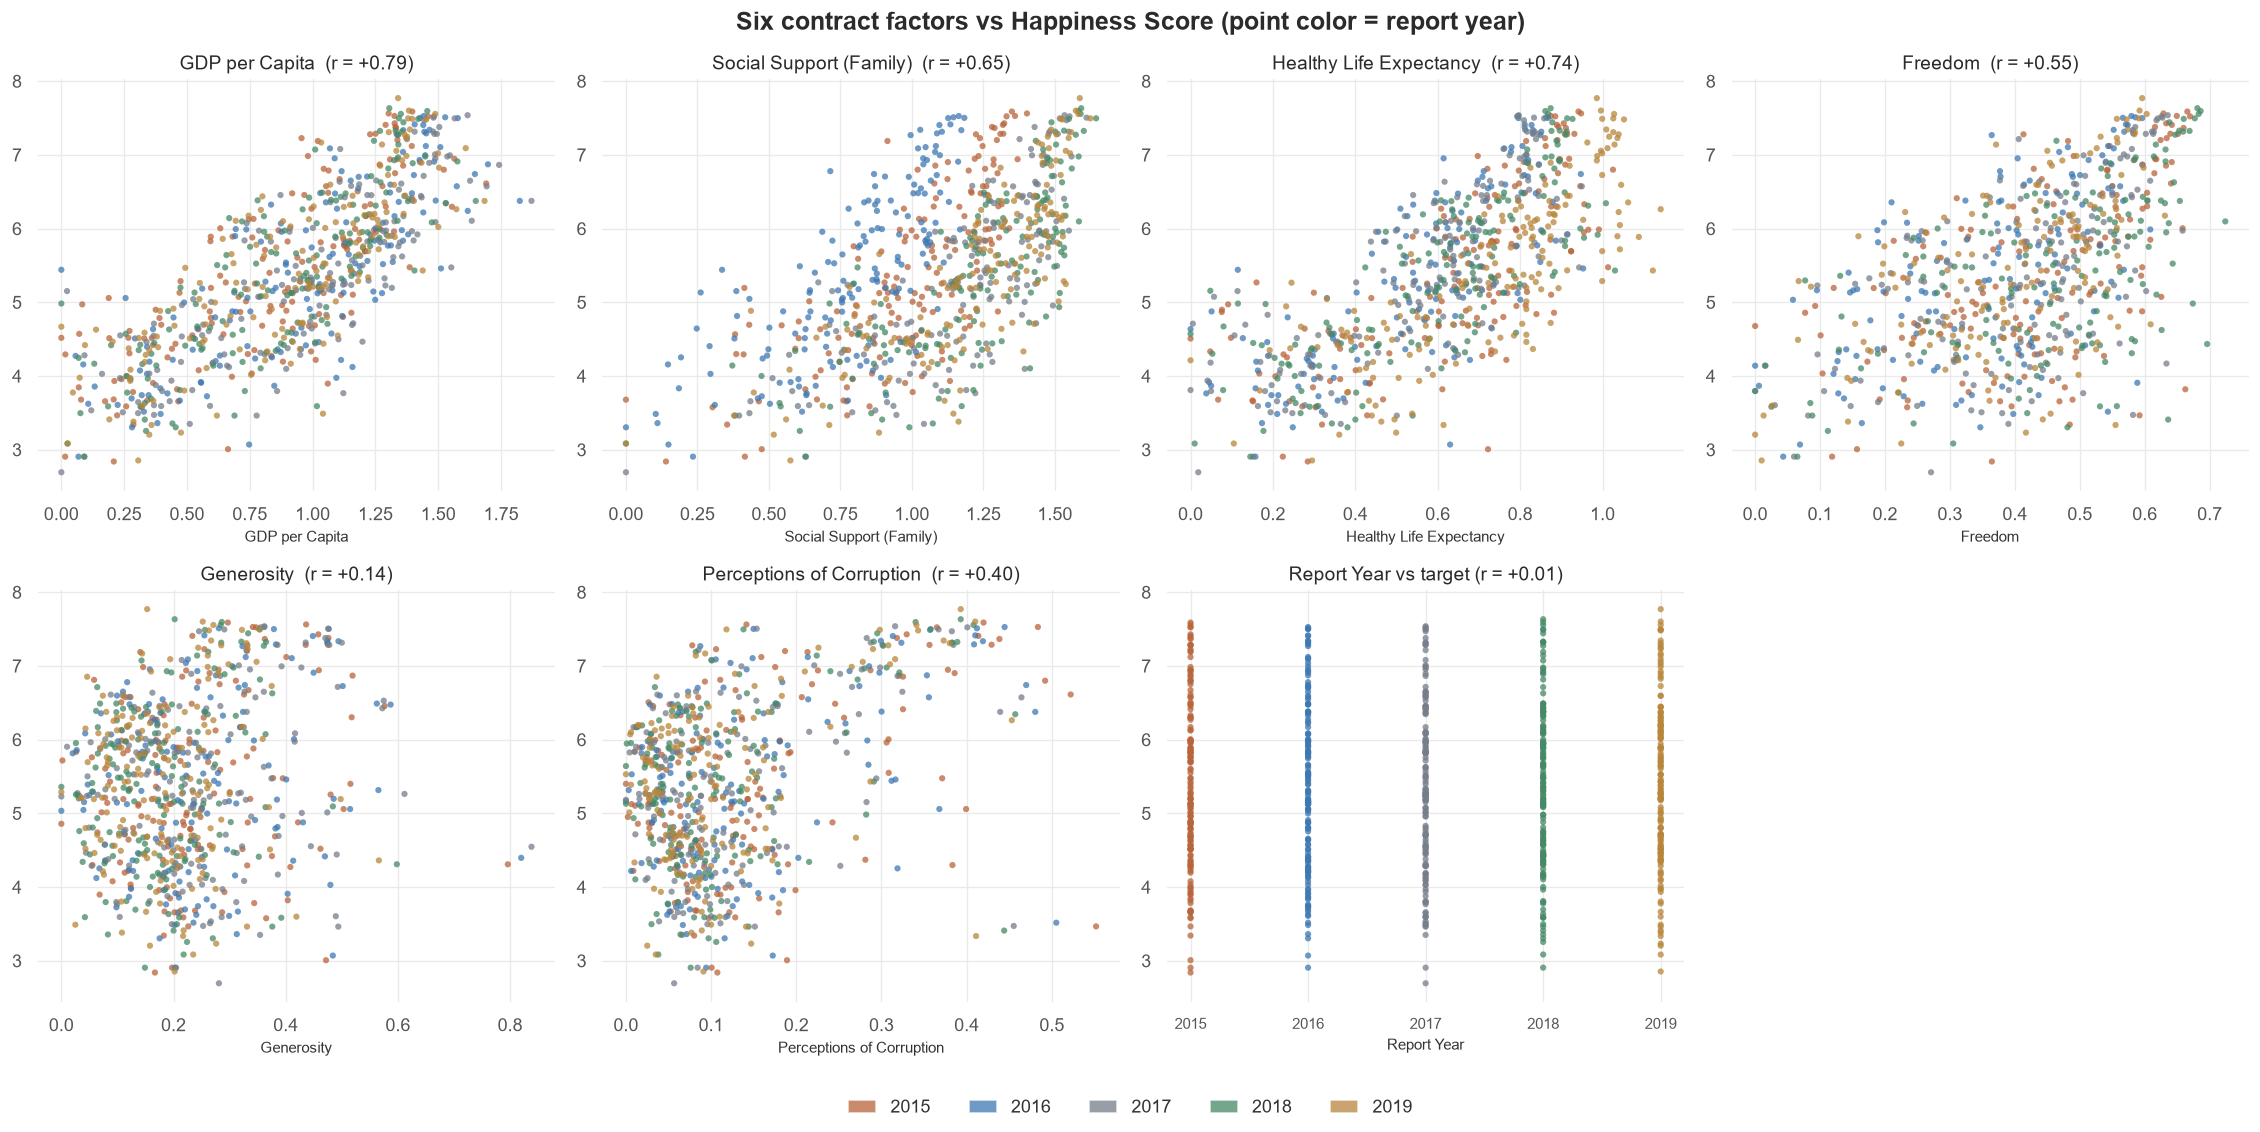

In [3]:
# Scatter panels: each of the 6 contract factors vs the target, colored by year
fig, axes = plt.subplots(2, 4, figsize=(19, 9.5), dpi=120)
fig.suptitle("Six contract factors vs Happiness Score (point color = report year)",
             fontsize=15, fontweight="bold", color="#2B2B2B")
for ax, f in zip(axes.flat, FEATURES_ORDERED := ["gdp", "family", "health",
                                                 "freedom", "generosity", "corruption"]):
    assert f in df.columns and f != TARGET     # target never drawn as an axis variable
    r = float(df[[f, TARGET]].corr().iloc[0, 1])
    ax.scatter(df[f], df[TARGET], c=[YEAR_PALETTE[y] for y in df["year"]],
               s=14, alpha=0.75, edgecolors="none")
    ax.set_title(f"{FEATURE_LABELS[f]}  (r = {r:+.2f})", fontsize=11.5)
    ax.set_xlabel(FEATURE_LABELS[f], fontsize=9)
ax = axes.flat[6]
ax.set_title(f"{FEATURE_LABELS['year']} vs target (r = "
             f"{df['year'].corr(df[TARGET]):+.2f})", fontsize=11.5)
ax.scatter(df["year"], df[TARGET], c=[YEAR_PALETTE[y] for y in df["year"]],
           s=14, alpha=0.75, edgecolors="none")
ax.set_xticks(list(YEAR_PALETTE))                      # integer year ticks
ax.set_xticklabels([str(y) for y in YEAR_PALETTE], fontsize=9)
ax.set_xlabel(FEATURE_LABELS["year"], fontsize=9)
axes.flat[-1].axis("off")
sns.despine(left=True, bottom=True)

handles = [mpatches.Patch(facecolor=YEAR_PALETTE[y], alpha=0.75, label=str(y)) for y in YEAR_PALETTE]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False,
           handlelength=1.6, columnspacing=2.2, fontsize=10.5)
plt.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

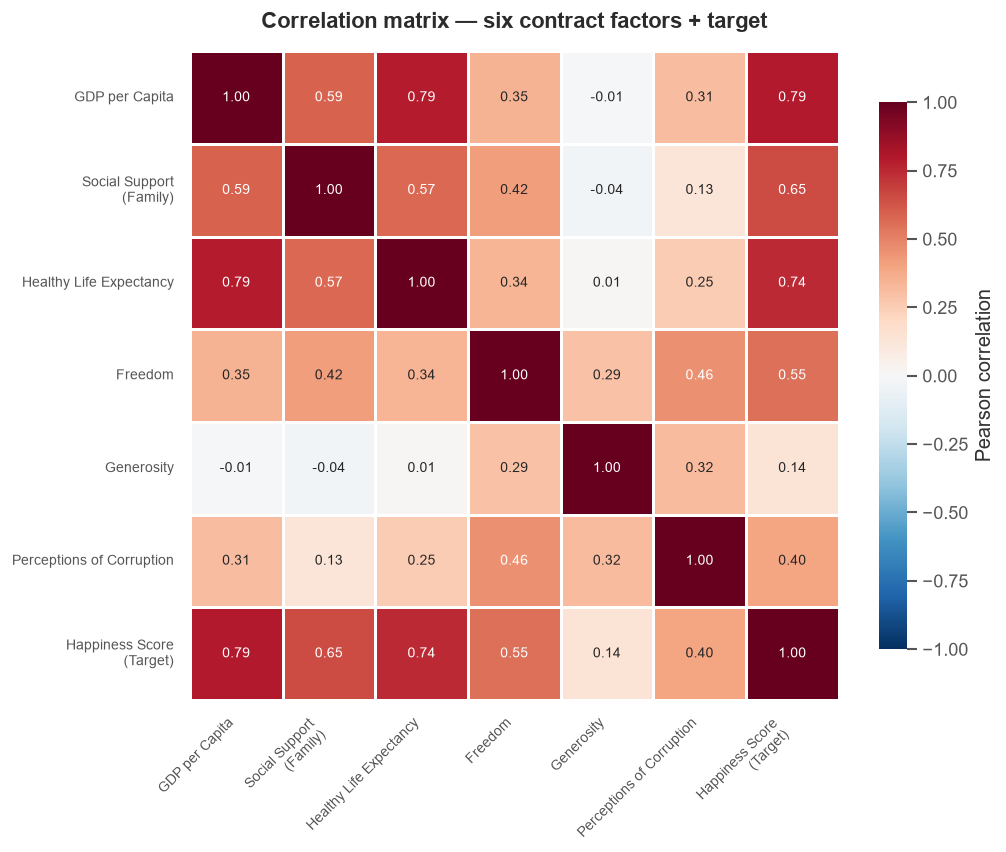

 correlations with the target:
gdp           0.790
family        0.651
health        0.743
freedom       0.553
generosity    0.138
corruption    0.398


In [4]:
# Correlation matrix: the 6 factors + the target (the target column is included ONLY as
# the read-only outcome column being correlated against, never as a model input)
corr = df[NUMERIC].corr()
assert corr.shape == (7, 7)

fig, ax = plt.subplots(figsize=(8.6, 7.2), dpi=120)
sns.heatmap(corr, annot=True, fmt=".2f", square=True,
            cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot_kws={"fontsize": 8.5},
            linewidths=0.8, linecolor="white",
            cbar_kws={"shrink": 0.82, "label": "Pearson correlation"},
            xticklabels=[FEATURE_LABELS[c].replace(" (", "\n(") for c in corr.columns],
            yticklabels=[FEATURE_LABELS[c].replace(" (", "\n(") for c in corr.index],
            ax=ax)
ax.set_title("Correlation matrix — six contract factors + target", fontsize=13,
             fontweight="bold", color="#2B2B2B", pad=14)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.tick_params(axis="x", labelsize=8.5)
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.show()

print(" correlations with the target:")
print(df[NUMERIC].corr()[TARGET].drop(TARGET).round(3).to_string())

## 4.2 and 4.3 Feature selection: leakage-free, order-frozen

**Why exactly these six features — and nothing else.** The model can only use variables
that (a) arrive inside the streaming event, (b) are numbers, and (c) do not reveal the
answer by construction. The six contract factors — `gdp`, `family` (social support),
`health` (healthy life expectancy), `freedom`, `generosity`, `corruption` (perceived
corruption, i.e. trust in institutions) — satisfy all three: the event JSON carries each
of them, they are all numeric floats, and the visuals and matrix above show they carry real
signal about the target (`gdp` r ≈ 0.79, `health` r ≈ 0.74, `family` r ≈ 0.65, `freedom`
r ≈ 0.55; `generosity` is weak, r ≈ 0.14, but stays in because the contract fixes the
feature set and it behaves as expected — a small independent effect).

**Why the target is never a feature.** `happiness_score` is the outcome the model must
predict (it arrives in the streaming event as `actual_happiness_score` and is used ONLY to
evaluate predictions afterwards). Feeding it (or anything derived from it) as an input
would make the model "read its own answer": the same-country correlation is 1.00 by
definition. For the same reason the raw report columns that were dropped by the cleaning
step — official rank, `Standard Error`, confidence intervals / whiskers, and
`Dystopia Residual` (the score minus the six factors) — never re-enter here.

**Why `country` and any regional label are NOT features.** `country` is a
high-cardinality identifier: with ~164 distinct values it would act as a memorization
lookup, it is the natural/event key (used to route Kafka messages), not a measured factor,
and one-hot-encoding it would add hundreds of sparse columns to a 781-row table. A
`region` label is excluded twice over: it only exists in the 2015–2016 raw files (nothing
to use for 2017–2019) and it is not part of the streaming event contract.

**Should the report `year` be a feature? (quick quantitative test).** The EDA showed the
factor *scales* changed across report editions (social support and life expectancy step
sharply at the 2016→2017 and 2018→2019 boundaries), so `year` plausibly helps the model
absorb the editions' weight changes — although its direct correlation with the target is
practically zero (r ≈ 0.006), which suggests any gain is about scale compensation, not
extra signal. The block below measures it honestly: an identical 70/30 split
(`random_state=42`), a `Pipeline` whose `StandardScaler` is fitted ONLY on the training
rows, and test-set MAE / RMSE / R² for **6 features (default)** vs
**7 features (+ `year`)** — the streaming event does carry a year field, so this option
would be implementable; the question is purely whether it buys accuracy.

In [5]:
# identical split & procedure for both variants; scaler sees ONLY training rows
FEATURES_ORDERED = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
assert TARGET not in FEATURES_ORDERED and "year" not in FEATURES_ORDERED
assert df[FEATURES_ORDERED].isna().sum().sum() == 0 and df[TARGET].isna().sum() == 0

y = df[TARGET]
X6 = df[FEATURES_ORDERED]
X7 = df[FEATURES_ORDERED + ["year"]]
X6_train, X6_test, X7_train, X7_test, y_train, y_test = train_test_split(
    X6, X7, y, test_size=0.30, random_state=42)

def fit_and_score(X_train, X_test):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
    pipe.fit(X_train, y_train)                      # scaler + model fitted on TRAIN only
    out = {"n_train": len(y_train), "n_test": len(y_test)}
    for tag, X in (("train", X_train), ("test", X_test)):
        pred = pipe.predict(X)
        out[f"MAE_{tag}"] = round(float(mean_absolute_error(y_test if tag == 'test' else y_train, pred)), 4)
        out[f"RMSE_{tag}"] = round(float(np.sqrt(mean_squared_error(y_test if tag == 'test' else y_train, pred))), 4)
        out[f"R2_{tag}"] = round(float(r2_score(y_test if tag == 'test' else y_train, pred)), 4)
    return pipe, out

results = {}
for label, X_train, X_test in (("6 features (default)", X6_train, X6_test),
                               ("7 features (+ year)", X7_train, X7_test)):
    _, results[label] = fit_and_score(X_train, X_test)
metrics_table = pd.DataFrame(results).T[
    ["MAE_test", "RMSE_test", "R2_test", "MAE_train", "RMSE_train", "R2_train"]]
display(metrics_table)

,MAE_test,RMSE_test,R2_test,MAE_train,RMSE_train,R2_train
6 features (default),0.4321,0.5566,0.7519,0.4225,0.5448,0.7675
7 features (+ year),0.4201,0.5438,0.7632,0.4208,0.5363,0.7748


**Reading of the comparison (numbers above are the recorded evidence).**

* Default 6 features (test): `MAE ≈ 0.432`, `RMSE ≈ 0.557`, `R² ≈ 0.752`.
* Adding the report `year` as a 7th feature (test): `MAE ≈ 0.420`, `RMSE ≈ 0.544`,
  `R² ≈ 0.763` — a real but **modest** gain of roughly `−0.012` MAE (≈ 2.8 %), `−0.013`
  RMSE (≈ 2.3 %) and `+0.011` R², consistent with `year` compensating the 2016→2017 and
  2018→2019 factor-scale breaks rather than adding new information (`corr(year, score) ≈
  0.006`).
* **Decision: keep the 6 contract features as the default.** The gain does not justify
  framing the model's behavior around the report-edition calendar, the 6-factor version
  already explains ≈ 75 % of the score variance on unseen rows, and the event contract's
  model-relevant payload is exactly those six factors. The comparison stays recorded in
  the build log; the final training (next section, same notebook) trains the 6-feature
  contract model, and the with-`year` numbers stand available if the team later confirms
  the small gain for the extra feature.

## 4.4 Preprocessing inside an sklearn `Pipeline` and the frozen feature order

The inference path must be identical to the training path, down to the ORDER of the
columns. Everything below is frozen now:

* `FEATURES` — the EXACT list (and order) used for training AND at inference time.
* A `Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])` — the
  scaler is part of the fitted object, so at inference the event row is scaled with the
  statistics learned on the training rows only (no leakage, no separate scaler file).

In [6]:
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
FEATURE_PIPELINE = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

print("FEATURES :", FEATURES)
print("TARGET   :", TARGET, "(never scaled, never fed to the model)")
print("pipeline :", [f"{name}: {type(step).__name__}" for name, step in FEATURE_PIPELINE.steps])

# Fit the contract pipeline on the TRAIN split only and verify every guarantee
FEATURE_PIPELINE.fit(X6_train, y_train)

scaler = FEATURE_PIPELINE.named_steps["scaler"]
model = FEATURE_PIPELINE.named_steps["model"]
print()
print("fitted on", int(scaler.n_samples_seen_), "rows (the training split only)")
print("scaler  feature_names_in_ =", scaler.feature_names_in_.tolist(), "-> matches FEATURES:",
      list(scaler.feature_names_in_) == FEATURES)
print("pipeline feature_names_in_ =", FEATURE_PIPELINE.feature_names_in_.tolist(),
      "-> matches FEATURES:", list(FEATURE_PIPELINE.feature_names_in_) == FEATURES)
print("model coef_ length =", len(model.coef_), "(one per feature, in FEATURES order)")

# 1) fit statistics come from the training rows and ONLY them
scaled_train = scaler.transform(X6_train)
print()
print("scaled TRAIN mean |max|:", float(np.abs(scaled_train.mean(axis=0)).max()), "(expected ~0)")
print("scaled TRAIN std |dev| :", float(np.abs(scaled_train.std(axis=0) - 1).max()),
      "(expected ~0 on the rows the scaler saw)")

# 2) an inference-shaped row: only the 6 features, in the frozen order
one_row = X6_test.iloc[[0]]
scaled_one = scaler.transform(one_row)
print()
print("inference example: 1 row x", scaled_one.shape[1], "scaled features, in FEATURES order")
print("prediction for that row:", float(FEATURE_PIPELINE.predict(one_row)[0]),
      "| actual:", float(y_test.iloc[0]))

FEATURES : ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
TARGET   : happiness_score (never scaled, never fed to the model)
pipeline : ['scaler: StandardScaler', 'model: LinearRegression']

fitted on 546 rows (the training split only)
scaler  feature_names_in_ = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption'] -> matches FEATURES: True
pipeline feature_names_in_ = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption'] -> matches FEATURES: True
model coef_ length = 6 (one per feature, in FEATURES order)

scaled TRAIN mean |max|: 4.505960114595873e-16 (expected ~0)
scaled TRAIN std |dev| : 2.220446049250313e-16 (expected ~0 on the rows the scaler saw)

inference example: 1 row x 6 scaled features, in FEATURES order
prediction for that row: 4.516045915340442 | actual: 4.35


## Final checks

In [7]:
checks = [
    ("processed CSV loaded: exactly 781 x 9", df.shape == (781, 9)),
    ("no missing values / no duplicated (country, year)",
     df.isna().sum().sum() == 0 and df.duplicated(["country", "year"]).sum() == 0),
    ("FEATURES frozen at the exact contract order",
     FEATURES == ["gdp", "family", "health", "freedom", "generosity", "corruption"]),
    ("target and year are NOT features",
     TARGET not in FEATURES and "year" not in FEATURES),
    ("all features numeric float64 in the dataset",
     all(df[f].dtype == np.float64 for f in FEATURES)),
    ("scaler fitted on the training split only",
     int(scaler.n_samples_seen_) == len(X6_train)),
    ("pipeline feature order equals FEATURES after fit",
     list(scaler.feature_names_in_) == FEATURES
     and list(FEATURE_PIPELINE.feature_names_in_) == FEATURES),
    ("1 coefficient per feature (linear model)",
     len(model.coef_) == len(FEATURES) and model.intercept_ is not None),
    ("scaled training rows: mean ~0 and std ~1 (fitted statistics)",
     float(np.abs(scaled_train.mean(axis=0)).max()) < 1e-8
     and float(np.abs(scaled_train.std(axis=0) - 1).max()) < 1e-8),
    ("correlation matrix is 7 x 7 (6 factors + target)", corr.shape == (7, 7)),
    ("with/without-year comparison measured on the SAME split",
     metrics_table.shape == (2, 6) and metrics_table["R2_test"].max() > 0.5),
    ("default kept 6 features (R2 gap between variants < 0.05)",
     abs(metrics_table["R2_test"].iloc[1] - metrics_table["R2_test"].iloc[0]) < 0.05),
]
final_checks = pd.DataFrame(checks, columns=["check", "result"])
final_checks["result"] = final_checks["result"].map({True: "PASS", False: "FAIL"})
print(final_checks.to_string(index=False))
assert final_checks["result"].eq("PASS").all(), "feature engineering checks failed!"
print()
print("Feature engineering complete; the next section in this notebook trains on these terms.")

                                                       check result
                       processed CSV loaded: exactly 781 x 9   PASS
           no missing values / no duplicated (country, year)   PASS
                 FEATURES frozen at the exact contract order   PASS
                            target and year are NOT features   PASS
                 all features numeric float64 in the dataset   PASS
                    scaler fitted on the training split only   PASS
            pipeline feature order equals FEATURES after fit   PASS
                    1 coefficient per feature (linear model)   PASS
scaled training rows: mean ~0 and std ~1 (fitted statistics)   PASS
            correlation matrix is 7 x 7 (6 factors + target)   PASS
     with/without-year comparison measured on the SAME split   PASS
    default kept 6 features (R2 gap between variants < 0.05)   PASS

Feature engineering complete; the next section in this notebook trains on these terms.


---

## 5. Model training, evaluation and artifact export (Part A, Step 4)

The feature-engineering section froze the inputs; this section trains the final model on
them, evaluates it, and exports the two artifacts the streaming layer consumes.

**One model only, deliberately: multiple linear regression (OLS).** The target
`happiness_score` is a continuous index, so binary classification models (e.g. logistic
regression) or count models (e.g. Poisson regression) simply do not apply. Ordinary least
squares inside a `Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])`
with the 6 contract features already explains ≈ 75 % of the variance on unseen rows,
stays fully interpretable (one standardized coefficient per factor — direct, honest
ammunition for the presentation), and adds zero deployment complexity: the streaming
consumer loads ONE pickle object. Tree ensembles and other heavy machinery would add
hyperparameters and hurt interpretability for, at best, a couple of R² points on a
781-row, textbook-linear problem — the scatter panels above already show there is nothing
strongly non-linear left on the table.

**Train/test discipline.** A single deterministic split is reused everywhere in this
notebook: 70 / 30 with `random_state=42` → **546 training rows / 235 test rows**. The
scaler is fitted ONLY on the training rows (it lives inside the fitted pipeline, so the
consumer never rescales anything with fresh statistics). The streaming layer will later
publish **ONLY the 235 test rows**, so the dashboards always evaluate predictions on data
the model never saw during training — the system never grades its own homework.

In [8]:
# 5.1 the ONE deterministic split of this notebook (already created above with random_state=42)
assert FEATURES == ["gdp", "family", "health", "freedom", "generosity", "corruption"]
assert len(X6_train) == 546 and len(X6_test) == 235, (len(X6_train), len(X6_test))
assert len(X6_train) + len(X6_test) == len(df) == 781

# 5.2 final training: exclusively the training rows, 6 contract features, frozen order
final_pipeline = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
final_pipeline.fit(X6_train[FEATURES], y_train)
print("trained:", len(y_train), "rows x", len(FEATURES), "features")
print("pipeline feature order:", list(final_pipeline.feature_names_in_))
print("scaler saw rows       :", int(final_pipeline.named_steps['scaler'].n_samples_seen_))

trained: 546 rows x 6 features
pipeline feature order: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
scaler saw rows       : 546


In [9]:
# 5.2b statistical interpretation table: standardized coefficients (effect per +1 SD of
# the feature, all on a comparable scale) and their equivalent on the ORIGINAL feature
# scale (effect per +1 raw unit) — plus the intercept, converted to both scales
scaler_f = final_pipeline.named_steps["scaler"]
lin_f = final_pipeline.named_steps["model"]

coef_table = pd.DataFrame({
    "feature": FEATURES,
    "coef_per_1SD": [round(float(v), 4) for v in lin_f.coef_],
    "feature_std_dev": [round(float(s), 4) for s in scaler_f.scale_],
    "coef_per_raw_unit": [round(float(c) / float(s), 4) for c, s in zip(lin_f.coef_, scaler_f.scale_)],
})
intercept_original = float(lin_f.intercept_) - float(
    np.sum(np.asarray(lin_f.coef_) / scaler_f.scale_ * scaler_f.mean_))
coef_table = pd.concat(
    [pd.DataFrame({"feature": ["(Intercept)"],
                   "coef_per_1SD": [round(float(lin_f.intercept_), 4)],
                   "feature_std_dev": [np.nan],
                   "coef_per_raw_unit": [round(intercept_original, 4)]}),
     coef_table],
    ignore_index=True)
print("'coef_per_1SD'      : score change for +1 standard deviation of the feature")
print("'coef_per_raw_unit' : score change for +1 raw unit of the feature")
print()
display(coef_table)
print("intercept (original scale) =", round(intercept_original, 4),
      "| intercept (standardized) =", round(float(lin_f.intercept_), 4))
strongest = coef_table.iloc[1:].assign(abs_=coef_table.iloc[1:]["coef_per_1SD"].abs()) \
    .sort_values("abs_", ascending=False)["feature"].tolist()
print()
print("features strongest -> weakest by standardized effect:")
print("   " + "  >  ".join(strongest))

'coef_per_1SD'      : score change for +1 standard deviation of the feature
'coef_per_raw_unit' : score change for +1 raw unit of the feature



,feature,coef_per_1SD,feature_std_dev,coef_per_raw_unit
0,(Intercept),5.3665,NaN,2.1799
1,gdp,0.4314,0.4047,1.0660
2,family,0.2103,0.3337,0.6302
3,health,0.2672,0.2520,1.0606
4,freedom,0.2486,0.1540,1.6148
5,generosity,0.0677,0.1207,0.5611
6,corruption,0.0992,0.1026,0.9664


intercept (original scale) = 2.1799 | intercept (standardized) = 5.3665

features strongest -> weakest by standardized effect:
   gdp  >  health  >  freedom  >  family  >  corruption  >  generosity


In [10]:
# 5.3 evaluation: MAE / RMSE / R^2 on BOTH splits (the train vs test gap is the overfit check)
eval_rows = []
for tag, X, yt in (("train", X6_train, y_train), ("test", X6_test, y_test)):
    pred = final_pipeline.predict(X)
    eval_rows.append({"split": tag, "n_rows": len(yt),
                      "MAE": round(float(mean_absolute_error(yt, pred)), 4),
                      "RMSE": round(float(np.sqrt(mean_squared_error(yt, pred))), 4),
                      "R2": round(float(r2_score(yt, pred)), 4)})
evaluation = pd.DataFrame(eval_rows).set_index("split")
display(evaluation)
pred_test = final_pipeline.predict(X6_test)
residuals_test = y_test.values - pred_test
print("overfit check: R2(train) - R2(test) =",
      round(float(evaluation.loc["train", "R2"] - evaluation.loc["test", "R2"]), 4),
      "(a small gap means no overfitting)")

,n_rows,MAE,RMSE,R2
split,,,,
train,546,0.4225,0.5448,0.7675
test,235,0.4321,0.5566,0.7519


overfit check: R2(train) - R2(test) = 0.0156 (a small gap means no overfitting)


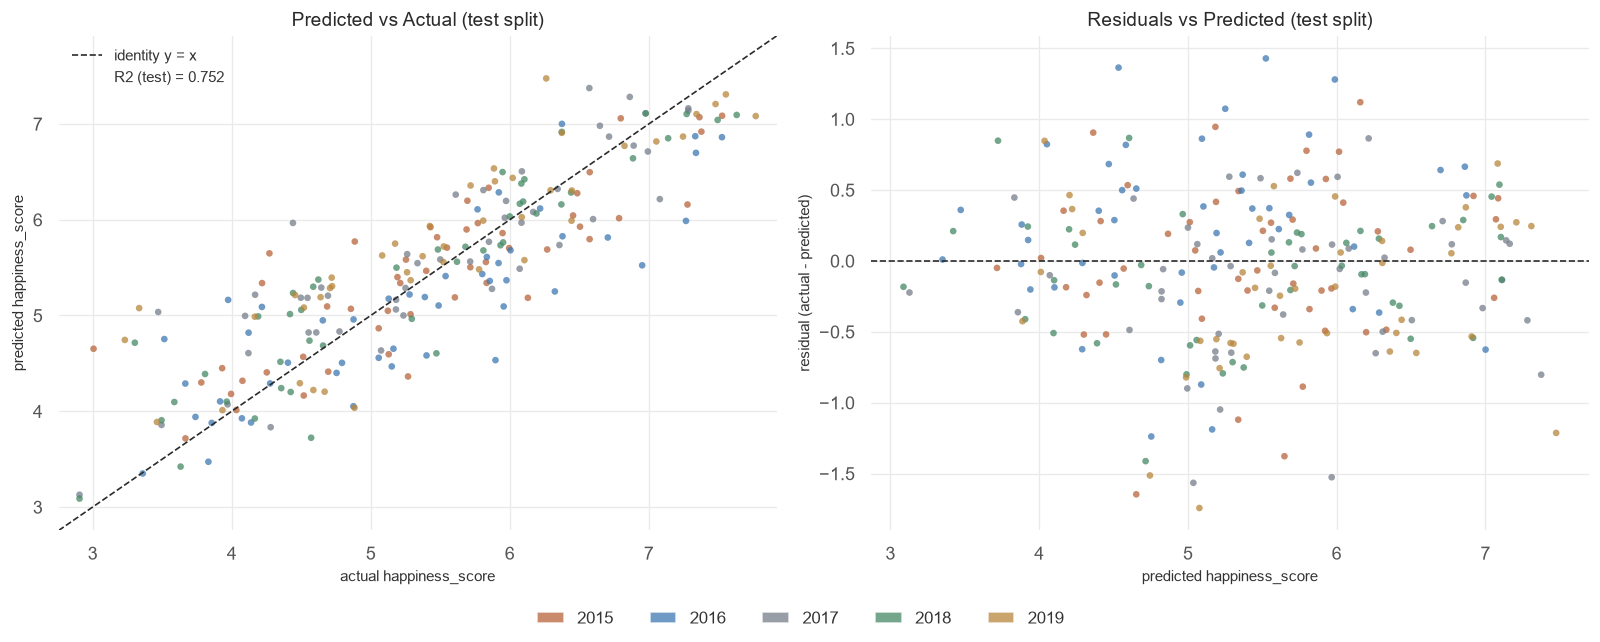

In [11]:
# 5.3b diagnostic panel (same minimal style): predicted vs actual with the identity
# line, and residuals vs predicted with the zero line; both colored by report year
test_years = df.loc[X6_test.index, "year"].values   # report year per test row
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), dpi=120)
pred_test_num = np.asarray(pred_test)
y_test_num = y_test.values
lo = float(min(y_test_num.min(), pred_test_num.min())) - 0.15
hi = float(max(y_test_num.max(), pred_test_num.max())) + 0.15

ax = axes[0]
for yr in YEAR_PALETTE:
    m = (test_years == yr)
    ax.scatter(y_test_num[m], pred_test_num[m], c=YEAR_PALETTE[yr], s=16,
               alpha=0.75, edgecolors="none")
ax.plot([lo, hi], [lo, hi], color="#2B2B2B", linewidth=1.0, linestyle="--", label="identity y = x")
ax.plot([], [], " ", label=f"R2 (test) = {float(evaluation.loc['test', 'R2']):.3f}")
ax.set_title("Predicted vs Actual (test split)", fontsize=11.5)
ax.set_xlabel("actual happiness_score", fontsize=9)
ax.set_ylabel("predicted happiness_score", fontsize=9)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[1]
for yr in YEAR_PALETTE:
    m = (test_years == yr)
    ax.scatter(pred_test_num[m], residuals_test[m], c=YEAR_PALETTE[yr], s=16,
               alpha=0.75, edgecolors="none")
ax.axhline(0, color="#2B2B2B", linewidth=1.0, linestyle="--")
ax.set_title("Residuals vs Predicted (test split)", fontsize=11.5)
ax.set_xlabel("predicted happiness_score", fontsize=9)
ax.set_ylabel("residual (actual - predicted)", fontsize=9)

sns.despine(left=True, bottom=True)
handles = [mpatches.Patch(facecolor=YEAR_PALETTE[yr], alpha=0.75, label=str(yr))
           for yr in YEAR_PALETTE]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False,
           handlelength=1.6, columnspacing=2.2, fontsize=10)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### 5.4 and 5.5 Export the two artifacts

* `models/model.pkl` — the COMPLETE fitted pipeline (scaler + coefficients), loaded later
  by the consumer to score stream events.
* `data/streaming/test_split.csv` — the 235 test rows with the 9 unified columns in the
  same clean order. The producer streams ONLY these rows, so the KPIs (average prediction
  error, per-country views, predicted vs actual, trends) are always computed on data the
  model did not train on. `happiness_score` travels in the split so the producer can map
  it to the event's `actual_happiness_score` field for later evaluation.

In [12]:
# 5.4 + 5.5 export (idempotent by design: re-running this notebook simply re-writes both files)
import joblib

MODELS_DIR = ROOT / "models"
STREAM_DIR = ROOT / "data" / "streaming"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
STREAM_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "model.pkl"
SPLIT_PATH = STREAM_DIR / "test_split.csv"

joblib.dump(final_pipeline, MODEL_PATH)

# the test split keeps the FULL unified row (the 9 unified columns, in that order),
# in the deterministic split order, clean UTF-8 CSV without index
test_split = df.loc[X6_test.index, UNIFIED].reset_index(drop=True)
assert test_split.shape == (235, 9), f"unexpected test split shape: {test_split.shape}"
assert list(test_split.columns) == UNIFIED, "test split must keep the unified column order"
assert "happiness_score" in test_split.columns          # -> the event's actual_happiness_score
test_split.to_csv(SPLIT_PATH, index=False, encoding="utf-8", lineterminator="\n")

print("wrote", MODEL_PATH.relative_to(ROOT), f"({MODEL_PATH.stat().st_size:,} bytes)")
print("wrote", SPLIT_PATH.relative_to(ROOT),
      f"({SPLIT_PATH.stat().st_size:,} bytes; {len(test_split)} rows x {test_split.shape[1]} cols)")

wrote models\model.pkl (1,601 bytes)
wrote data\streaming\test_split.csv (18,234 bytes; 235 rows x 9 cols)


### 5.6 Sanity check: the artifact must work WITHOUT this notebook's memory

The pickle is reloaded and re-applied here, and — the strong version of the test — a
**brand-new Python interpreter** (a child process of this kernel) re-loads `model.pkl`,
re-reads `test_split.csv` from disk and predicts the first row; the prediction must be
numerically EXACTLY equal to the in-memory pipeline's prediction.

In [13]:
# 5.6 in-notebook reload of the exported pipeline
import subprocess
import sys

reloaded_pipeline = joblib.load(MODEL_PATH)
row_df = test_split.iloc[[0]][FEATURES]        # 1 row, ONLY the 6 columns, FEATURES order
pred_inmemory = float(final_pipeline.predict(row_df)[0])
pred_reloaded = float(reloaded_pipeline.predict(row_df)[0])
print("row scored:", row_df.round(4).to_dict("records")[0])
print("prediction (in-memory pipeline):", pred_inmemory)
print("prediction (reloaded model.pkl) :", pred_reloaded)
assert pred_reloaded == pred_inmemory, "reloaded model diverges from the trained object!"

# 5.6 fresh-process verification: the same load/predict cycle run by a completely new
# interpreter, reading BOTH artifacts straight from disk
fresh_script = "\n".join([
    "import joblib, pandas as pd, sys",
    "model = joblib.load(sys.argv[1])",
    "row = pd.read_csv(sys.argv[2]).iloc[[0]]",
    "pred = model.predict(row[['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']])",
    "print(float(pred[0]))",
])
proc = subprocess.run([sys.executable, "-c", fresh_script,
                       MODEL_PATH.as_posix(), SPLIT_PATH.as_posix()],
                      capture_output=True, text=True, check=True, timeout=120)
pred_fresh = float(proc.stdout.strip())
print("prediction (fresh interpreter)  :", pred_fresh)
assert pred_fresh == pred_reloaded, "fresh-process prediction diverges!"
print()
print("OK: model.pkl works independently of this notebook, to the last digit.")

row scored: {'gdp': 0.308, 'family': 0.95, 'health': 0.391, 'freedom': 0.452, 'generosity': 0.22, 'corruption': 0.146}
prediction (in-memory pipeline): 4.516045915340442
prediction (reloaded model.pkl) : 4.516045915340442


prediction (fresh interpreter)  : 4.516045915340442

OK: model.pkl works independently of this notebook, to the last digit.


In [14]:
# 5.6c final checks of the training section (idempotent: everything is re-verified on
# every notebook run; the artifacts are simply re-exported and re-verified)
p5_checks = [
    ("ONE deterministic split reused everywhere: 546 train / 235 test",
     len(X6_train) == 546 and len(X6_test) == 235),
    ("final pipeline trained exclusively on the training rows, in FEATURES order",
     int(final_pipeline.named_steps["scaler"].n_samples_seen_) == 546
     and list(final_pipeline.feature_names_in_) == FEATURES),
    ("interpretation table: intercept + 6 coefficients",
     len(lin_f.coef_) == 6 and lin_f.intercept_ is not None and len(coef_table) == 7),
    ("evaluation reported for train AND test (test R2 > 0.5, test MAE < 0.5)",
     evaluation.shape == (2, 4) and evaluation.loc["test", "R2"] > 0.5
     and evaluation.loc["test", "MAE"] < 0.5),
    ("no overfitting (R2 train-test gap < 0.05)",
     float(evaluation.loc["train", "R2"] - evaluation.loc["test", "R2"]) < 0.05),
    ("models/model.pkl exists and reloads as the fitted pipeline",
     MODEL_PATH.exists()
     and list(joblib.load(MODEL_PATH).named_steps["scaler"].feature_names_in_) == FEATURES),
    ("data/streaming/test_split.csv exists: exactly 235 x 9 in the unified column order",
     SPLIT_PATH.exists() and pd.read_csv(SPLIT_PATH).shape == (235, 9)
     and list(pd.read_csv(SPLIT_PATH).columns) == UNIFIED),
    ("test split carries the actual outcome column for the event mapping",
     "happiness_score" in pd.read_csv(SPLIT_PATH).columns
     and bool(pd.read_csv(SPLIT_PATH)["happiness_score"].notna().all())),
    ("streaming discipline: model never sees these rows in training",
     len(set(X6_test.index) & set(X6_train.index)) == 0),
    ("reloaded pickle prediction == in-memory prediction (exact float equality)",
     pred_reloaded == pred_inmemory),
    ("fresh-interpreter prediction == in-memory prediction (exact float equality)",
     pred_fresh == pred_inmemory),
]
p5_final = pd.DataFrame(p5_checks, columns=["check", "result"])
p5_final["result"] = p5_final["result"].map({True: "PASS", False: "FAIL"})
print(p5_final.to_string(index=False))
assert p5_final["result"].eq("PASS").all(), "training/artifact checks failed!"
print()
print("READY for the streaming layer: the model artifacts are exported and independently verified.")

                                                                            check result
                  ONE deterministic split reused everywhere: 546 train / 235 test   PASS
       final pipeline trained exclusively on the training rows, in FEATURES order   PASS
                                 interpretation table: intercept + 6 coefficients   PASS
           evaluation reported for train AND test (test R2 > 0.5, test MAE < 0.5)   PASS
                                        no overfitting (R2 train-test gap < 0.05)   PASS
                       models/model.pkl exists and reloads as the fitted pipeline   PASS
data/streaming/test_split.csv exists: exactly 235 x 9 in the unified column order   PASS
               test split carries the actual outcome column for the event mapping   PASS
                    streaming discipline: model never sees these rows in training   PASS
        reloaded pickle prediction == in-memory prediction (exact float equality)   PASS
      fresh-interpret